# GraphRAG：基于图的检索增强生成

## 概述

GraphRAG 是一款先进的问答系统，它结合了基于图的知识表示和检索增强生成技术。该系统处理输入文档，构建丰富的知识图谱，并利用该知识图谱增强用户查询的检索和答案生成。GraphRAG 利用自然语言处理、机器学习和图论，提供更准确、更符合上下文的答案。

## 动机

传统的检索增强生成系统通常难以在长文档中保持上下文关联，也难以建立相关信息之间的联系。GraphRAG 通过以下方式解决这些局限性：

1. 将知识表示为互连图，从而更好地保留概念之间的关系。

2. 在查询过程中实现更智能的信息遍历。

3. 提供信息在回答过程中如何连接和访问的可视化表示。

## 关键组件

1. **文档处理器**：负责输入文档的初始处理，创建文本块和嵌入。

2. **知识图谱**：构建已处理文档的图表示，其中节点代表文本块，边代表它们之间的关系。

3. **查询引擎**：利用知识图谱和向量存储来管理用户查询的响应过程。

4. **可视化工具**：创建图的可视化表示以及响应查询所采用的遍历路径。

## 方法详情

1. **文档处理**：

- 将输入文档分割成易于管理的文本块。

- 使用语言模型对每个文本块进行嵌入。

- 基于这些嵌入创建一个向量存储，以便进行高效的相似性搜索。

2. **知识图谱构建**：

- 为每个文本块创建图节点。

- 使用自然语言处理 (NLP) 技术和语言模型的组合，从每个数据块中提取概念。

- 对提取的概念进行词形还原，以提高匹配度。

- 基于语义相似性和共享概念，在节点之间添加边。

- 计算边的权重，以表示关系的强度。

3. **查询处理**：

- 嵌入用户查询，并用于从向量存储中检索相关文档。

- 初始化一个优先级队列，其中包含与最相关文档对应的节点。

- 系统采用类似 Dijkstra 的算法遍历知识图谱：

* 根据节点的优先级（与查询的连接强度）依次探索节点。

* 对于每个已探索的节点：

- 将其内容添加到上下文中。

- 系统检查当前上下文是否提供了完整的答案。

- 如果答案不完整：

* 处理该节点的概念，并将其添加到已访问概念集中。

* 探索相邻节点，并根据边的权重更新它们的优先级。

* 如果找到更强的关联，则将节点添加到优先级队列中。

- 此过程持续进行，直到找到完整答案或优先级队列耗尽为止。

- 如果在遍历图后仍未找到完整答案，系统将使用累积的上下文和大型语言模型生成最终答案。

4. **可视化**：

- 知识图谱以节点表示文本块、边表示关系的方式进行可视化。

- 边的颜色表示关系的强度（权重）。

- 用于回答查询的遍历路径用弯曲的虚线箭头突出显示。

- 遍历的起始节点和结束节点使用不同的颜色，以便于识别。

## 此方法的优势

1. **增强上下文感知**：通过将知识表示为图，系统可以更好地维护上下文，并在输入文档的不同部分之间建立联系。

2. **增强检索**：图结构支持更智能的信息检索，超越了简单的关键词匹配。

3. **可解释的结果**：图和遍历路径的可视化能够帮助用户了解系统如何得出答案，从而提升透明度和可信度。

4. **灵活的知识表示**：图结构能够轻松地整合新出现的信息和关系。

5. **高效的信息遍历**：图中的加权边使系统能够在回答查询时优先处理最相关的信息路径。

![GraphRAG流程图展示](graph_rag.svg "演示")

In [4]:
from importlib.metadata import version
print("nltk version:", version("nltk"))
print("spacy version:", version("spacy"))
print("networkx version:", version("networkx"))
print("langchain version:", version("langchain"))
print("langchain_community version:", version("langchain_community"))
print("langchain_text_splitters version:", version("langchain_text_splitters"))
print("langchain_core version:", version("langchain_core"))
print("langchain_classic version:", version("langchain_classic"))
print("langchain_openai version:", version("langchain_openai"))

nltk version: 3.8.2
spacy version: 3.8.11
networkx version: 3.2.1
langchain version: 1.2.10
langchain_community version: 0.4.1
langchain_text_splitters version: 1.1.1
langchain_core version: 1.2.16
langchain_classic version: 1.0.0
langchain_openai version: 0.3.12


In [5]:
import networkx as nx
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.prompts import PromptTemplate
from langchain_classic.retrievers import ContextualCompressionRetriever
from langchain_classic.retrievers.document_compressors import LLMChainExtractor
from langchain_community.callbacks import get_openai_callback
from langchain_community.document_loaders import PyPDFLoader
from langchain_openai import ChatOpenAI
from langchain_openai import OpenAIEmbeddings

from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pydantic import BaseModel, Field
import os
import sys
from dotenv import load_dotenv
from typing import List, Tuple, Dict
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import nltk
import spacy
import heapq

from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm
import numpy as np

from spacy.cli import download
from spacy.lang.en import English

# 加载环境变量 .env，OPENAI_API_KEY 和 OPENAI_BASE_URL
load_dotenv()
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# 下载nltk的资源，句子分割punkt和语义关系网络
nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)

True

## 定义DocumentProcessor类

In [6]:
class DocumentProcessor:
    def __init__(self):
        """
        使用文本分割器和 OpenAI 词嵌入初始化 DocumentProcessor。
        
        属性：
        - text_splitter：具有指定块大小和重叠的 RecursiveCharacterTextSplitter 实例。
        - embeddings：用于嵌入文档的 OpenAIEmbeddings 实例。
        """
        self.text_splitter = RecursiveCharacterTextSplitter(chunk_size=1200, chunk_overlap=100)
        self.embeddings = OpenAIEmbeddings()

    def process_documents(self, documents):
        """
        处理文档列表，将其分割成更小的块并创建向量存储。
        
        参数：
        - documents（字符串列表）：待处理的文档列表。
        
        返回值：
        - tuple：包含以下内容的元组：
        - splits（字符串列表）：分割后的文档块列表。
        - vector_store（FAISS）：由分割后的文档块及其嵌入向量创建的 FAISS 向量存储。
        """
        splits = self.text_splitter.split_documents(documents)
        vector_store = FAISS.from_documents(splits, self.embeddings) # meta
        return splits, vector_store

    def create_embeddings_batch(self, texts, batch_size=32):
        """
        分批为文本列表创建词嵌入。
        
        参数：
        - texts（字符串列表）：要嵌入词嵌入的文本列表。
        - batch_size（整数，可选）：每批处理的文本数量。默认值为 32。
        
        返回值：
        - numpy.ndarray：输入文本的词嵌入数组。
        """
        embeddings = []
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i + batch_size]
            batch_embeddings = self.embeddings.embed_documents(batch)
            embeddings.extend(batch_embeddings)
        return np.array(embeddings)

    def compute_similarity_matrix(self, embeddings):
        """
        计算给定一组词嵌入的余弦相似度矩阵。
        
        参数：
        - embeddings (numpy.ndarray): 词嵌入数组。
        
        返回值：
        - numpy.ndarray: 输入词嵌入的余弦相似度矩阵。 # [N, N]
        """
        return cosine_similarity(embeddings)



# 定义Concepts class

In [7]:
class Concepts(BaseModel):
    concepts_list: List[str] = Field(description="List of concepts")

# 定义 KnowledgeGraph class

In [8]:
class KnowledgeGraph:
    def __init__(self):
        """
        使用图、词形还原器和自然语言处理模型初始化知识图谱。
        
        属性：
        - graph：networkx 图的实例。
        - lemmatizer：WordNetLemmatizer 的实例。
        - concept_cache：用于缓存提取概念的字典。
        - nlp：spaCy 自然语言处理模型的实例。
        - edges_threshold：一个浮点值，用于设置基于相似度添加边的阈值。
        """
        self.graph = nx.Graph()   # 建图
        self.lemmatizer = WordNetLemmatizer() # 词行还原
        self.concept_cache = {}
        self.nlp = self._load_spacy_model() # 识别实体
        self.edges_threshold = 0.8

    def build_graph(self, splits, llm, embedding_model):
        """
        通过添加节点、创建嵌入、提取概念和添加边来构建知识图谱。
        
        参数：
        - splits（列表）：文档分割列表。
        - llm：大模型实例。
        - embedding_model：嵌入模型实例。
        
        返回值：
        - 无
        """
        self._add_nodes(splits)
        embeddings = self._create_embeddings(splits, embedding_model)
        self._extract_concepts(splits, llm)
        self._add_edges(embeddings)

    def _add_nodes(self, splits):
        """
        根据文档拆分结果向图中添加节点。
        
        参数：
        - splits（列表）：文档拆分列表。
        
        返回值：
        - 无
        """
        for i, split in enumerate(splits):
            self.graph.add_node(i, content=split.page_content)

    def _create_embeddings(self, splits, embedding_model):
        """
        使用嵌入模型为文档分割创建嵌入向量。
        
        参数：
        - splits（列表）：文档分割列表。
        - embedding_model：嵌入模型实例。
        
        返回值：
        - numpy.ndarray：文档分割嵌入向量数组。
        """
        texts = [split.page_content for split in splits]
        return embedding_model.embed_documents(texts)

    def _compute_similarities(self, embeddings):
        """
        计算词嵌入的余弦相似度矩阵。
        
        参数：
        - embeddings (numpy.ndarray): 词嵌入数组。
        
        返回值：
        - numpy.ndarray: 词嵌入的余弦相似度矩阵。
        """
        return cosine_similarity(embeddings)

    def _load_spacy_model(self):
        """
        加载 spaCy NLP 模型，必要时下载。
        
        参数：
        - 无
        
        返回值：
        - spacy.Language：spaCy NLP 模型的实例。
        """
        try:
            return spacy.load("en_core_web_sm")
        except OSError:
            print("Downloading spaCy model...")
            download("en_core_web_sm")
            return spacy.load("en_core_web_sm")

    def _extract_concepts_and_entities(self, content, llm):
        """
        使用 spaCy 和大型语言模型从内容中提取概念和命名实体。
        
        参数：
        - content (str)：要从中提取概念和实体的内容。
        - llm：大型语言模型的实例。
        
        返回值：
        - list：提取的概念和实体列表。
        """
        if content in self.concept_cache:
            return self.concept_cache[content]

        # 使用spaCy抽取实体
        doc = self.nlp(content)
        # 抽取人名，组织机构名（谷歌、联合国、清华大学），地理政治实体（中国，欧洲，加州，上海），艺术作品（蒙娜丽莎、哈利·波特、月光奏鸣曲）
        named_entities = [ent.text for ent in doc.ents if ent.label_ in ["PERSON", "ORG", "GPE", "WORK_OF_ART"]]

        # 使用大模型抽取concepts（通用概念）
        concept_extraction_prompt = PromptTemplate(
            input_variables=["text"],
            template="Extract key concepts (excluding named entities) from the following text:\n\n{text}\n\nKey concepts:"
        )
        concept_chain = concept_extraction_prompt | llm.with_structured_output(Concepts)
        general_concepts = concept_chain.invoke({"text": content}).concepts_list

        # 把实体和通用概念融合起来作为图节点
        all_concepts = list(set(named_entities + general_concepts))

        self.concept_cache[content] = all_concepts
        return all_concepts

    def _extract_concepts(self, splits, llm):
        """
        使用多线程提取所有文档分割的概念。
        
        参数：
        - splits（列表）：文档分割列表。
        - llm：大型语言模型实例。
        
        返回值：
        - 无
        """
        with ThreadPoolExecutor() as executor:
            future_to_node = {executor.submit(self._extract_concepts_and_entities, split.page_content, llm): i
                              for i, split in enumerate(splits)}

            for future in tqdm(as_completed(future_to_node), total=len(splits),
                               desc="Extracting concepts and entities"):
                node = future_to_node[future]
                concepts = future.result()
                # 每个节点包含实体 + 通用概念
                self.graph.nodes[node]['concepts'] = concepts

    def _add_edges(self, embeddings):
        """
        根据词嵌入的相似性和共享概念，向图中添加边。
        
        参数：
        - embeddings (numpy.ndarray): 文档分割的词嵌入数组。
        
        返回值：
        - 无
        """
        similarity_matrix = self._compute_similarities(embeddings) # N * N
        num_nodes = len(self.graph.nodes)

        for node1 in tqdm(range(num_nodes), desc="Adding edges"):
            for node2 in range(node1 + 1, num_nodes):
                similarity_score = similarity_matrix[node1][node2] # 文本分片之间embedding相似度
                # 如果节点间的embedding相似度大于阈值
                if similarity_score > self.edges_threshold:
                    shared_concepts = set(self.graph.nodes[node1]['concepts']) & set(
                        self.graph.nodes[node2]['concepts'])
                    edge_weight = self._calculate_edge_weight(node1, node2, similarity_score, shared_concepts)
                    self.graph.add_edge(node1, node2, weight=edge_weight,
                                        similarity=similarity_score,
                                        shared_concepts=list(shared_concepts))

    def _calculate_edge_weight(self, node1, node2, similarity_score, shared_concepts, alpha=0.7, beta=0.3):
        """
        基于相似度得分和共享概念计算边的权重。
        
        参数：
        - node1 (int)：第一个节点。
        - node2 (int)：第二个节点。
        - similarity_score (float)：节点间的相似度得分。
        - shared_concepts (set)：节点间的共享概念集合。
        - alpha (float，可选)：相似度得分的权重。默认值为 0.7。
        - beta (float，可选)：共享概念的权重。默认值为 0.3。
        
        返回值：
        - float：计算出的边的权重。
        """
        max_possible_shared = min(len(self.graph.nodes[node1]['concepts']), len(self.graph.nodes[node2]['concepts']))
        normalized_shared_concepts = len(shared_concepts) / max_possible_shared if max_possible_shared > 0 else 0
        return alpha * similarity_score + beta * normalized_shared_concepts

    def _lemmatize_concept(self, concept):
        """
        对给定概念进行词形还原。例如running → run，cars → car。
        
        参数：
        - concept (str): 要还原的概念。
        
        返回值：
        - str: 还原后的概念。
        """
        return ' '.join([self.lemmatizer.lemmatize(word) for word in concept.lower().split()])


# 定义AnswerCheck类

In [9]:
class AnswerCheck(BaseModel):
    is_complete: bool = Field(description="Whether the current context provides a complete answer to the query")
    answer: str = Field(description="The current answer based on the context, if any")

# 定义QueryEngine类

In [10]:
class QueryEngine:
    def __init__(self, vector_store, knowledge_graph, llm):
        self.vector_store = vector_store
        self.knowledge_graph = knowledge_graph
        self.llm = llm
        self.max_context_length = 4000
        self.answer_check_chain = self._create_answer_check_chain()

    def _create_answer_check_chain(self):
        """
        创建一个链，用于检查上下文是否提供了查询的完整答案。
        
        参数：
        - 无
        
        返回值：
        - 链：用于检查上下文是否提供了完整答案的链。
        """
        answer_check_prompt = PromptTemplate(
            input_variables=["query", "context"],
            template="Given the query: '{query}'\n\nAnd the current context:\n{context}\n\nDoes this context provide a complete answer to the query? If yes, provide the answer. If no, state that the answer is incomplete.\n\nIs complete answer (Yes/No):\nAnswer (if complete):"
        )
        return answer_check_prompt | self.llm.with_structured_output(AnswerCheck)

    def _check_answer(self, query: str, context: str) -> Tuple[bool, str]:
        """
        检查当前上下文是否能提供查询的完整答案。
        
        参数：
        - query (str): 要回答的查询。
        - context (str): 当前上下文。
        
        返回值：
        - tuple: 包含以下内容的元组：
        - is_complete (bool): 上下文是否能提供完整答案。
        - answer (str): 如果上下文完整，则返回基于上下文的答案。
        """
        response = self.answer_check_chain.invoke({"query": query, "context": context})
        return response.is_complete, response.answer

    def _expand_context(self, query: str, relevant_docs) -> Tuple[str, List[int], Dict[int, str], str]:
        """
        该方法通过类似 Dijkstra 算法的方式遍历知识图谱来扩展上下文。
        此方法实现了 Dijkstra 算法的改进版本，用于探索知识图谱，优先处理最相关且连接性最强的信息。算法的工作原理如下：
        
        1. 初始化：
        - 从对应于最相关文档的节点开始。
        - 使用优先级队列来管理遍历顺序，优先级基于节点之间的连接强度（weight）。
        - 维护一个字典，其中包含到每个节点的最佳已知“距离”（连接强度的倒数）。
        
        2. 遍历：
        - 始终优先探索优先级最高（连接最强）的节点。
        - 对于每个节点，检查是否已找到完整答案。
        - 探索节点的邻居节点，如果发现更强的连接，则更新其优先级。
        
        3. 概念处理：
        - 跟踪已访问的概念，以引导探索找到新的相关信息。
        - 仅当邻居节点引入新概念时才进行扩展。
        
        4. 终止条件：
        - 如果找到完整答案，则停止。
        - 继续执行，直到优先级队列为空（所有可达节点均已探索完毕）。
        
        此方法确保：
        - 优先处理最相关且关联性最强的信息。
        - 系统地探索新概念。
        - 通过追踪知识图谱中最强的关联性来找到最相关的答案。
        
        参数：
        - query (str)：待解答的查询。
        - relevant_docs (List[Document])：用于开始遍历的相关文档列表。
        
        返回值：
        - tuple：包含以下内容的元组：
        - expanded_context (str)：从已遍历节点中累积的上下文。
        - traversal_path (List[int])：访问的节点索引序列。
        - filtered_content (Dict[int, str])：节点索引到其内容的映射。
        - final_answer (str)：找到的最终答案（如有）。
  
        """
        # 初始化变量
        expanded_context = ""
        traversal_path = []
        visited_concepts = set()
        filtered_content = {}
        final_answer = ""

        priority_queue = []
        distances = {}  # 存储到每个节点的最佳已知“距离”（连接强度的倒数）

        print("\nTraversing the knowledge graph:")

        # 根据相关文档，使用距离最近的节点初始化优先级队列。
        for doc in relevant_docs:
            # 在知识图谱中为每个相关文档找到最相似的节点
            closest_nodes = self.vector_store.similarity_search_with_score(doc.page_content, k=1)
            closest_node_content, similarity_score = closest_nodes[0]

            # 获取知识图谱中对应的节点
            closest_node = next(n for n in self.knowledge_graph.graph.nodes if
                                self.knowledge_graph.graph.nodes[n]['content'] == closest_node_content.page_content)

            # 初始化优先级（最小堆行为的相似度得分的倒数）， 因为用的是最小堆，所以priority越小，优先级越高
            priority = 1 / similarity_score
            heapq.heappush(priority_queue, (priority, closest_node))
            distances[closest_node] = priority

        step = 0
        while priority_queue:
            # 获取优先级最高（距离值最低）的节点
            current_priority, current_node = heapq.heappop(priority_queue)

            # 如果已经找到到达此节点的更佳路径，则跳过
            if current_priority > distances.get(current_node, float('inf')):
                continue

            if current_node not in traversal_path:
                step += 1
                traversal_path.append(current_node)
                node_content = self.knowledge_graph.graph.nodes[current_node]['content']
                node_concepts = self.knowledge_graph.graph.nodes[current_node]['concepts']

                # 将节点内容添加到我们累积的上下文中
                filtered_content[current_node] = node_content
                expanded_context += "\n" + node_content if expanded_context else node_content # content  + 1st_node_content

                # 记录当前步骤，以便调试和可视化
                print(f"\nStep {step} - Node {current_node}:")
                print(f"Content: {node_content[:100]}...")
                print(f"Concepts: {', '.join(node_concepts)}")
                print("-" * 50)

                # 检查我们是否在当前上下文中得到了完整的答案
                is_complete, answer = self._check_answer(query, expanded_context)
                if is_complete:
                    final_answer = answer
                    break

                # 处理当前节点的概念
                node_concepts_set = set(self.knowledge_graph._lemmatize_concept(c) for c in node_concepts)
                if not node_concepts_set.issubset(visited_concepts): # 如果当前节点没有发现新实体或概念，则继续下一个节点的处理
                    visited_concepts.update(node_concepts_set)

                    # 探索邻居
                    for neighbor in self.knowledge_graph.graph.neighbors(current_node):
                        edge_data = self.knowledge_graph.graph[current_node][neighbor]
                        edge_weight = edge_data['weight']

                        # 计算到邻居的新距离（优先级）
                        # 注意：我们使用 1 / edge_weight，因为权重越高表示连接越强
                        distance = current_priority + (1 / edge_weight) # 

                        # 如果我们发现与邻居的连接更强，则更新其距离。距离越小，说明联系越紧密
                        if distance < distances.get(neighbor, float('inf')): # a, => (b, c, d)  
                            distances[neighbor] = distance
                            heapq.heappush(priority_queue, (distance, neighbor))

                            # 如果邻居节点尚未位于我们的遍历路径中，则处理该节点
                            if neighbor not in traversal_path:
                                step += 1
                                traversal_path.append(neighbor)
                                neighbor_content = self.knowledge_graph.graph.nodes[neighbor]['content']
                                neighbor_concepts = self.knowledge_graph.graph.nodes[neighbor]['concepts']

                                filtered_content[neighbor] = neighbor_content
                                # content  + 1st_node_content + 2nd_node_content
                                expanded_context += "\n" + neighbor_content if expanded_context else neighbor_content 

                                # 记录邻居节点信息
                                print(f"\nStep {step} - Node {neighbor} (neighbor of {current_node}):")
                                print(f"Content: {neighbor_content[:100]}...")
                                print(f"Concepts: {', '.join(neighbor_concepts)}")
                                print("-" * 50)

                                # 添加邻居的内容后，检查答案是否完整
                                is_complete, answer = self._check_answer(query, expanded_context)
                                if is_complete:
                                    final_answer = answer
                                    break

                                # 处理邻居的概念
                                neighbor_concepts_set = set(
                                    self.knowledge_graph._lemmatize_concept(c) for c in neighbor_concepts)
                                if not neighbor_concepts_set.issubset(visited_concepts):
                                    visited_concepts.update(neighbor_concepts_set)

                # 如果找到了最终答案，则跳出主循环
                if final_answer:
                    break

        # 如果还没有找到完整的答案，请使用 LLM 生成一个答案（兜底方案）
        if not final_answer:
            print("\nGenerating final answer...")
            response_prompt = PromptTemplate(
                input_variables=["query", "context"],
                template="Based on the following context, please answer the query.\n\nContext: {context}\n\nQuery: {query}\n\nAnswer:"
            )
            response_chain = response_prompt | self.llm
            input_data = {"query": query, "context": expanded_context}
            final_answer = response_chain.invoke(input_data)

        return expanded_context, traversal_path, filtered_content, final_answer

    def query(self, query: str) -> Tuple[str, List[int], Dict[int, str]]:
        """
        通过检索相关文档、扩展上下文并生成最终答案来处理查询。
        
        参数：
        - query (str): 要回答的查询。
        
        返回值：
        - tuple: 包含以下内容的元组：
        - final_answer (str): 查询的最终答案。
        - traversal_path (list): 知识图谱中节点的遍历路径。
        - filtered_content (dict): 节点的过滤内容。
        """
        with get_openai_callback() as cb:
            print(f"\nProcessing query: {query}")
            # 检索相关的文档块
            relevant_docs = self._retrieve_relevant_documents(query)
            # 根据相关文档，扩展上下文
            expanded_context, traversal_path, filtered_content, final_answer = self._expand_context(query, relevant_docs)
            if not final_answer:
                print("\nGenerating final answer...")
                response_prompt = PromptTemplate(
                    input_variables=["query", "context"],
                    template="Based on the following context, please answer the query.\n\nContext: {context}\n\nQuery: {query}\n\nAnswer:"
                )

                response_chain = response_prompt | self.llm
                input_data = {"query": query, "context": expanded_context}
                response = response_chain.invoke(input_data)
                final_answer = response
            else:
                print("\nComplete answer found during traversal.")

            print(f"\nFinal Answer: {final_answer}")
            print(f"\nTotal Tokens: {cb.total_tokens}")
            print(f"Prompt Tokens: {cb.prompt_tokens}")
            print(f"Completion Tokens: {cb.completion_tokens}")
            print(f"Total Cost (USD): ${cb.total_cost}")

        return final_answer, traversal_path, filtered_content

    def _retrieve_relevant_documents(self, query: str):
        """
        使用向量存储，根据查询检索相关文档。
        
        参数：
        - query (str)：要回答的查询。
        
        返回值：
        - list：相关文档列表。
        """
        print("\nRetrieving relevant documents...")
        
        # 从向量数据库中检索与问题最相似的 top-k 个相关文档块
        retriever = self.vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 5})
        
        # 对第一层检索到的文档块进行智能压缩，只提取与问题最相关的部分，将压缩后的有效信息合并
        # 对每个文档块，让 LLM 判断哪些内容与问题真正相关，然后只保留这些关键信息
        compressor = LLMChainExtractor.from_llm(self.llm)
        compression_retriever = ContextualCompressionRetriever(base_compressor=compressor, base_retriever=retriever)
        
        return compression_retriever.invoke(query)


# 定义Visualizer类

In [11]:
class Visualizer:
    @staticmethod
    def visualize_traversal(graph, traversal_path):
        """
        可视化知识图谱上的遍历路径，节点、边和遍历路径均高亮显示。
        
        参数：
        - graph (networkx.Graph): 包含节点和边的知识图谱。
        - traversal_path (int 列表): 表示遍历路径的节点索引列表。
        
        返回值：
        - None
        """
        traversal_graph = nx.DiGraph()

        # 从原始图中添加节点和边
        for node in graph.nodes():
            traversal_graph.add_node(node)
        for u, v, data in graph.edges(data=True):
            traversal_graph.add_edge(u, v, **data)

        fig, ax = plt.subplots(figsize=(16, 12))

        # 生成所有节点的位置
        pos = nx.spring_layout(traversal_graph, k=1, iterations=50)

        # 根据粗细绘制带颜色的规则边缘
        edges = traversal_graph.edges()
        edge_weights = [traversal_graph[u][v].get('weight', 0.5) for u, v in edges]
        nx.draw_networkx_edges(traversal_graph, pos,
                               edgelist=edges,
                               edge_color=edge_weights,
                               edge_cmap=plt.cm.Blues,
                               width=2,
                               ax=ax)

        # 绘制节点
        nx.draw_networkx_nodes(traversal_graph, pos,
                               node_color='lightblue',
                               node_size=3000,
                               ax=ax)

        # 用曲线箭头绘制遍历路径
        edge_offset = 0.1
        for i in range(len(traversal_path) - 1):
            start = traversal_path[i]
            end = traversal_path[i + 1]
            start_pos = pos[start]
            end_pos = pos[end]

            # 计算曲线的控制点
            mid_point = ((start_pos[0] + end_pos[0]) / 2, (start_pos[1] + end_pos[1]) / 2)
            control_point = (mid_point[0] + edge_offset, mid_point[1] + edge_offset)

            # 画弯箭头
            arrow = patches.FancyArrowPatch(start_pos, end_pos,
                                            connectionstyle=f"arc3,rad={0.3}",
                                            color='red',
                                            arrowstyle="->",
                                            mutation_scale=20,
                                            linestyle='--',
                                            linewidth=2,
                                            zorder=4)
            ax.add_patch(arrow)

        # 为节点准备标签
        labels = {}
        for i, node in enumerate(traversal_path):
            concepts = graph.nodes[node].get('concepts', [])
            label = f"{i + 1}. {concepts[0] if concepts else ''}"
            labels[node] = label

        for node in traversal_graph.nodes():
            if node not in labels:
                concepts = graph.nodes[node].get('concepts', [])
                labels[node] = concepts[0] if concepts else ''

        # 画出标签
        nx.draw_networkx_labels(traversal_graph, pos, labels, font_size=8, font_weight="bold", ax=ax)

        # 高亮显示起始节点和结束节点
        start_node = traversal_path[0]
        end_node = traversal_path[-1]

        nx.draw_networkx_nodes(traversal_graph, pos,
                               nodelist=[start_node],
                               node_color='lightgreen',
                               node_size=3000,
                               ax=ax)

        nx.draw_networkx_nodes(traversal_graph, pos,
                               nodelist=[end_node],
                               node_color='lightcoral',
                               node_size=3000,
                               ax=ax)

        ax.set_title("Graph Traversal Flow")
        ax.axis('off')

        # 添加边权重颜色条
        sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues,
                                   norm=plt.Normalize(vmin=min(edge_weights), vmax=max(edge_weights)))
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
        cbar.set_label('Edge Weight', rotation=270, labelpad=15)

        # 添加图例
        regular_line = plt.Line2D([0], [0], color='blue', linewidth=2, label='Regular Edge')
        traversal_line = plt.Line2D([0], [0], color='red', linewidth=2, linestyle='--', label='Traversal Path')
        start_point = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='lightgreen', markersize=15,
                                 label='Start Node')
        end_point = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='lightcoral', markersize=15,
                               label='End Node')
        legend = plt.legend(handles=[regular_line, traversal_line, start_point, end_point], loc='upper left',
                            bbox_to_anchor=(0, 1), ncol=2)
        legend.get_frame().set_alpha(0.8)

        plt.tight_layout()
        plt.show()

    @staticmethod
    def print_filtered_content(traversal_path, filtered_content):
        """
        按遍历顺序打印已访问节点的过滤内容。
        
        参数：
        - traversal_path（整数列表）：表示遍历路径的节点索引列表。
        - filtered_content（整数/字符串字典）：将节点索引映射到其过滤内容的字典。
        
        返回值：
        - 无
        """
        print("\nFiltered content of visited nodes in order of traversal:")
        for i, node in enumerate(traversal_path):
            print(f"\nStep {i + 1} - Node {node}:")
            print(
                f"Filtered Content: {filtered_content.get(node, 'No filtered content available')[:200]}...")  # Print first 200 characters
            print("-" * 50)


# 定义 GraphRAG类

In [12]:
class GraphRAG:
    def __init__(self, documents):
        """
        初始化 GraphRAG 系统，包括文档处理、知识图谱构建、查询和可视化等组件。
        
        参数：
        - documents（字符串列表）：待处理的文档列表。
        
        属性：
        - llm：用于生成响应的大型语言模型 (LLM) 实例。
        - embedding_model：用于文档嵌入的嵌入模型实例。
        - document_processor：用于处理文档的 DocumentProcessor 类实例。
        - knowledge_graph：用于构建和管理知识图谱的 KnowledgeGraph 类实例。
        - query_engine：用于处理查询的 QueryEngine 类实例（初始化为 None）。
        - visualizer：用于可视化知识图谱遍历的 Visualizer 类实例。
        """
        self.llm = ChatOpenAI(temperature=0, model_name="gpt-4o-mini", max_tokens=4000)
        self.embedding_model = OpenAIEmbeddings()
        self.document_processor = DocumentProcessor()
        self.knowledge_graph = KnowledgeGraph()
        self.query_engine = None
        self.visualizer = Visualizer()
        self.process_documents(documents)

    def process_documents(self, documents):
        """
        处理文档列表，将其分割成块，嵌入这些块，并构建知识图谱。
        
        参数：
        - documents（字符串列表）：待处理的文档列表。
        
        返回值：
        - 无
        """
        splits, vector_store = self.document_processor.process_documents(documents)
        self.knowledge_graph.build_graph(splits, self.llm, self.embedding_model)
        self.query_engine = QueryEngine(vector_store, self.knowledge_graph, self.llm)

    def query(self, query: str):
        """
        通过从知识图谱中检索相关信息并可视化遍历路径来处理查询。
        
        参数：
        - query (str): 要回答的查询。
        
        返回值：
        - str: 查询的响应。
        """
        response, traversal_path, filtered_content = self.query_engine.query(query)

        if traversal_path:
            self.visualizer.visualize_traversal(self.knowledge_graph.graph, traversal_path)
        else:
            print("No traversal path to visualize.")

        return response

# 查询入口

Adding edges: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 7412.07it/s]



Processing query: 气候变化的原因有哪些，请帮我分析一下主要因素，考虑全面一点

Retrieving relevant documents...

Traversing the knowledge graph:

Step 1 - Node 1:
Content: Modern scientific observations indicate a rapid increase in global temperatures, sea levels, 
and ex...
Concepts: greenhouse gases, human activities, methane, energy production, climate change, global temperatures, fossil fuels, greenhouse effect, CH4, climate predictions, extreme weather events, historical climate record, Fossil Fuels, natural processes, emission of greenhouse gases, carbon dioxide, nitrous oxide, The Intergovernmental Panel on Climate Change, sea levels
--------------------------------------------------

Step 2 - Node 0 (neighbor of 1):
Content: Understanding Climate Change 
Chapter 1: Introduction to Climate Change 
Climate change refers to si...
Concepts: Holocene, temperature, ice age, global climate, human activities, precipitation, weather patterns, climate change, historical climate changes, fossil fuels, global temperat

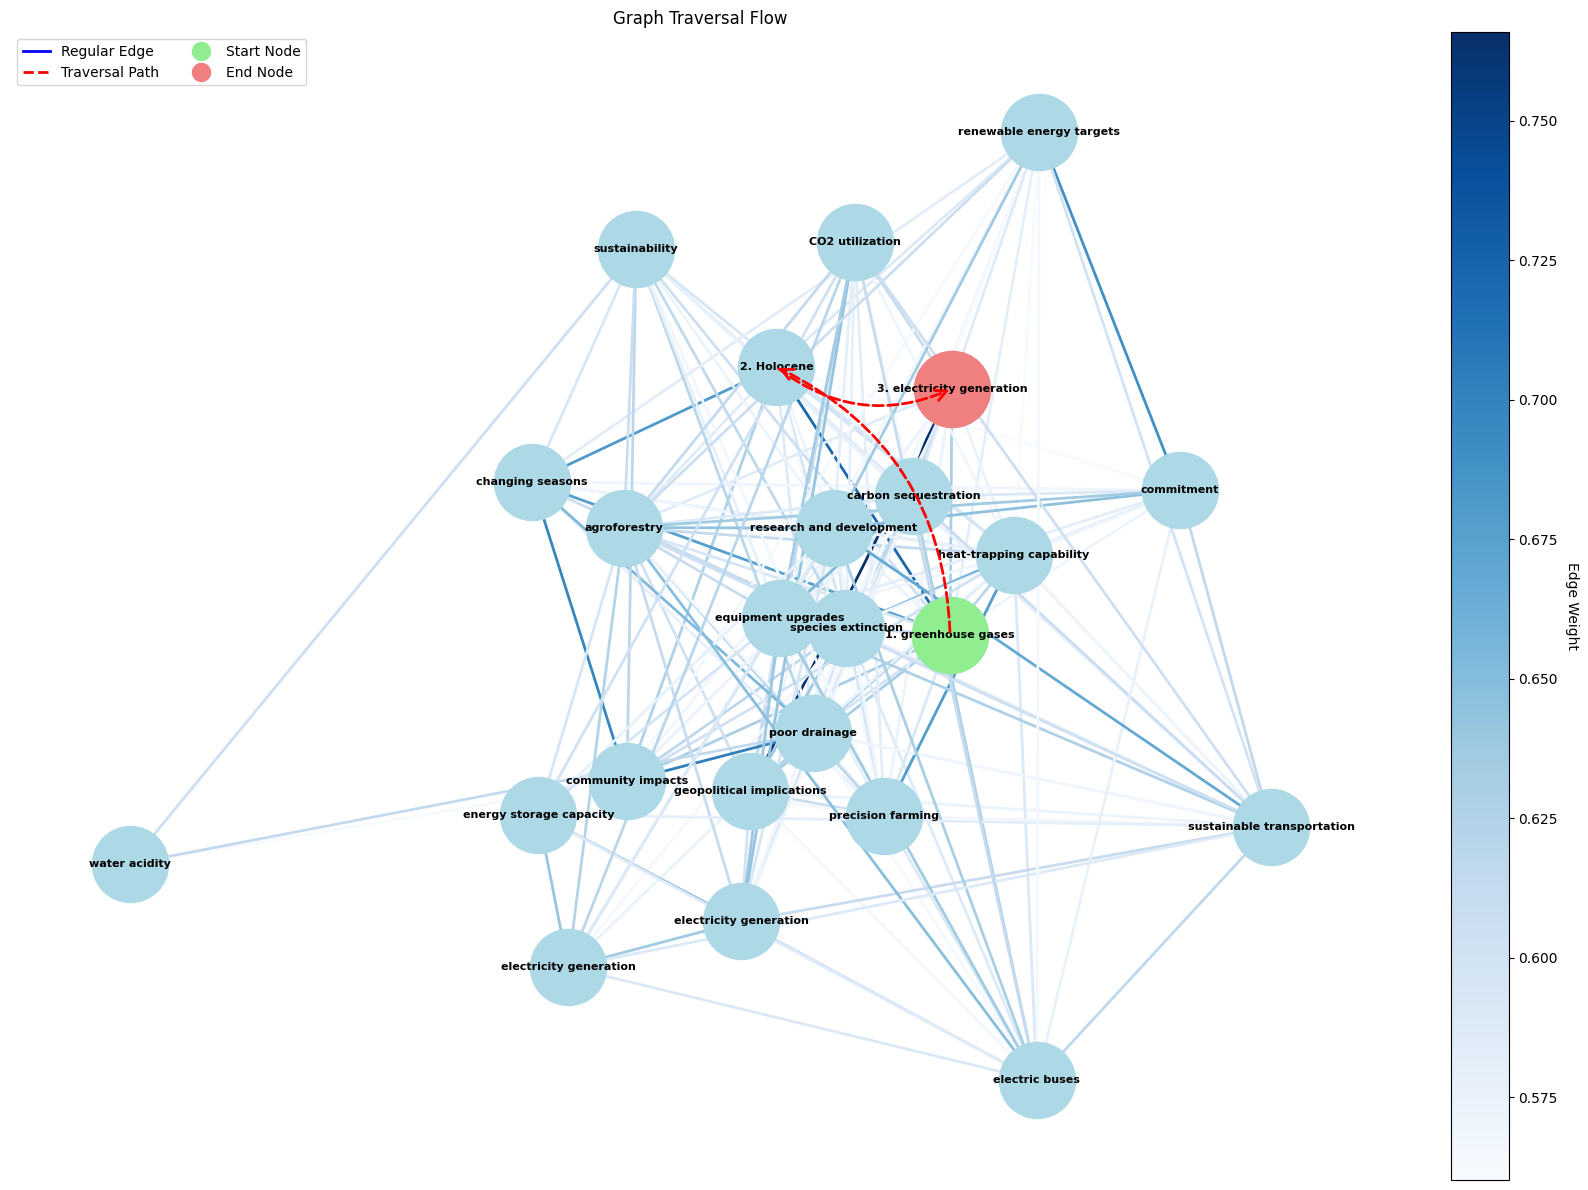

In [13]:
# 文件路径
pdf_path = "Understanding_Climate_Change.pdf"

# 查询query
query = "气候变化的原因有哪些，请帮我分析一下主要因素，考虑全面一点"

# 读取pdf
loader = PyPDFLoader(pdf_path)
documents = loader.load()

# 取前10页来建图
documents = documents[:10]

# 初始化GraphRAG实例
graph_rag = GraphRAG(documents)

# 输入查询并从 RAG 图中检索信息
response = graph_rag.query(query)